In [96]:
import geopandas as gpd
from matplotlib import pyplot as plt
from shapely.geometry.geo import shape
from shapely.geometry import box
from data.geo import meter_to_foot
from src.data.constants import (LOCAL_CRS, WORLD_CRS, WEB_CRS)
import contextily as cx
import pandas as pd


In [97]:
train_stations = gpd.read_file("../../data/interim/train_stations.geojson").to_crs(LOCAL_CRS)
bike_stations = gpd.read_parquet("../../data/final/bike_rides.geoparquet").to_crs(LOCAL_CRS)
mccormick_vehicle = gpd.read_file("../../data/raw/mccormick_vehicle.geojson").to_crs(LOCAL_CRS)
united_vehicle = gpd.read_file("../../data/raw/united_center_vehicle.geojson").to_crs(LOCAL_CRS)
tracts = gpd.read_parquet("../../data/interim/tracts.geoparquet").to_crs(LOCAL_CRS)

In [98]:
bike_stations = bike_stations.drop_duplicates(['geometry','distance_UNITED_CENTER','distance_HYATT_REGENCY_MCCORMICK_PLACE'])

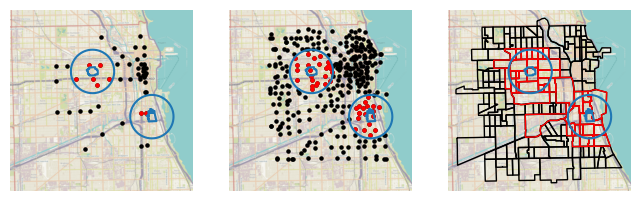

In [123]:
figs, axs = plt.subplots(1,3, figsize=(8,6), sharex=True, sharey=True)

uv_buffer = united_vehicle.centroid.buffer(meter_to_foot(1600))
mv_buffer = mccormick_vehicle.centroid.buffer(meter_to_foot(1600))
bbox = box(*pd.concat([uv_buffer, mv_buffer]).buffer(meter_to_foot(1600)).total_bounds)

near_train_stations_u = train_stations[train_stations.intersects(uv_buffer.iloc[0])]
near_train_stations_m = train_stations[train_stations.intersects(mv_buffer.iloc[0])]
near_bike_stations_u = bike_stations[bike_stations.intersects(uv_buffer.iloc[0])]
near_bike_stations_m = bike_stations[bike_stations.intersects(mv_buffer.iloc[0])]
near_tract_stations_u = tracts[tracts.intersects(uv_buffer.iloc[0])]
near_tract_stations_m = tracts[tracts.intersects(mv_buffer.iloc[0])]

bbox_train_stations = train_stations[train_stations.intersects(bbox)]
bbox_bike_stations = bike_stations[bike_stations.intersects(bbox)]
bbox_tract_stations = tracts[tracts.intersects(bbox)]

bbox_train_stations.to_crs(WEB_CRS).plot(ax=axs[0], color='k', markersize=5)
bbox_bike_stations.to_crs(WEB_CRS).plot(ax=axs[1], color='k', markersize=5)
bbox_tract_stations.to_crs(WEB_CRS).boundary.plot(ax=axs[2], color='k', linewidth=1)

near_train_stations_u.to_crs(WEB_CRS).plot(ax=axs[0], color='r', markersize=5)
near_train_stations_m.to_crs(WEB_CRS).plot(ax=axs[0], color='r', markersize=5)
near_bike_stations_u.to_crs(WEB_CRS).plot(ax=axs[1], color='r', markersize=5)
near_bike_stations_m.to_crs(WEB_CRS).plot(ax=axs[1], color='r', markersize=5)
near_tract_stations_u.to_crs(WEB_CRS).boundary.plot(ax=axs[2], color='r', linewidth=1)
near_tract_stations_m.to_crs(WEB_CRS).boundary.plot(ax=axs[2], color='r', linewidth=1)

for ax in axs:
    united_vehicle.boundary.to_crs(WEB_CRS).plot(ax=ax)
    mccormick_vehicle.boundary.to_crs(WEB_CRS).plot(ax=ax)
    uv_buffer.boundary.to_crs(WEB_CRS).plot(ax=ax)
    mv_buffer.boundary.to_crs(WEB_CRS).plot(ax=ax)
    ax.set_axis_off()
    ax.set_aspect('equal')
    cx.add_basemap(ax=ax, attribution=False)

figs.savefig('../../reports/replication/perimeters.png', dpi=300, bbox_inches='tight', pad_inches=0)
!cp ../../reports/replication/perimeters.png ../../../eric-mc2-cv/static/img

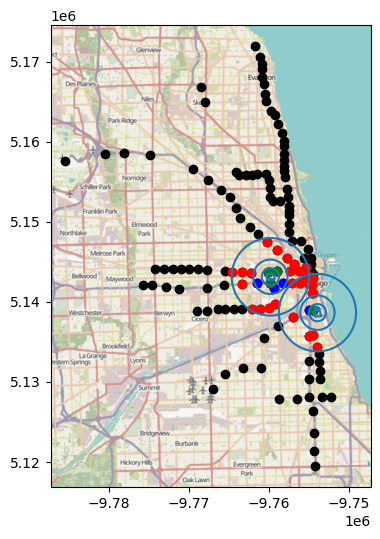

In [38]:
# figs, axs = plt.subplots(1,1, figsize=(8,6))
#
# united_vehicle.boundary.to_crs(WEB_CRS).plot(ax=axs)
# mccormick_vehicle.boundary.to_crs(WEB_CRS).plot(ax=axs)
#
# uv_buffer = united_vehicle.centroid.buffer(meter_to_foot(1600))
# mv_buffer = mccormick_vehicle.centroid.buffer(meter_to_foot(1600))
#
# uv_buffer_h = united_vehicle.centroid.buffer(meter_to_foot(800))
# mv_buffer_h = mccormick_vehicle.centroid.buffer(meter_to_foot(800))
#
# uv_buffer_2 = united_vehicle.centroid.buffer(meter_to_foot(3600))
# mv_buffer_2 = mccormick_vehicle.centroid.buffer(meter_to_foot(3600))
#
# uv_buffer.boundary.to_crs(WEB_CRS).plot(ax=axs)
# mv_buffer.boundary.to_crs(WEB_CRS).plot(ax=axs)
# uv_buffer_h.boundary.to_crs(WEB_CRS).plot(ax=axs)
# mv_buffer_h.boundary.to_crs(WEB_CRS).plot(ax=axs)
# uv_buffer_2.boundary.to_crs(WEB_CRS).plot(ax=axs)
# mv_buffer_2.boundary.to_crs(WEB_CRS).plot(ax=axs)
#
# near_train_stations_u = train_stations[train_stations.intersects(uv_buffer.iloc[0])]
# near_train_stations_m = train_stations[train_stations.intersects(mv_buffer.iloc[0])]
# near_train_stations_uh = train_stations[train_stations.intersects(uv_buffer_h.iloc[0])]
# near_train_stations_mh = train_stations[train_stations.intersects(mv_buffer_h.iloc[0])]
# near_train_stations_u2 = train_stations[train_stations.intersects(uv_buffer_2.iloc[0])]
# near_train_stations_m2 = train_stations[train_stations.intersects(mv_buffer_2.iloc[0])]
#
# train_stations.to_crs(WEB_CRS).plot(ax=axs, color='k')
# near_train_stations_u2.to_crs(WEB_CRS).plot(ax=axs, color='r')
# near_train_stations_m2.to_crs(WEB_CRS).plot(ax=axs, color='r')
# near_train_stations_u.to_crs(WEB_CRS).plot(ax=axs, color='b')
# near_train_stations_m.to_crs(WEB_CRS).plot(ax=axs, color='b')
# near_train_stations_uh.to_crs(WEB_CRS).plot(ax=axs, color='g')
# near_train_stations_mh.to_crs(WEB_CRS).plot(ax=axs, color='g')
# cx.add_basemap(ax=axs, attribution=False)